# Ground truth extraction

Following up on the station census in `notebook 01`, this notebook pulls the monthly averaged PM2.5 data from all the 
stations identified previously.

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [44]:
from pathlib import Path

import dotenv
import pickle
import gzip
import numpy as np
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import yaml

from openaq import OpenAQ

import monitoring_deserts.data.fetch_openaq as fetch_oaq

## Configuration

Read the configuration from the previous step, produced in `01_station_census.ipynb`.

In [3]:
# Run-specific settings
with open("../configs/census_scope.yaml") as f:
    run_config = yaml.safe_load(f)
    
BOUNDING_BOX = tuple(run_config["bounding_box"].values())
DAY_START, DAY_END = run_config["period"]["start"], run_config["period"]["end"]
PM25_PARAM_ID = run_config["pm25_parameter_id"]


# Generic settings
with open("../configs/project_config.yaml") as f:
    gen_config = yaml.safe_load(f)
    
RAW_DATA_DIR = Path(gen_config["data_dir"]["raw"]) / "ground_truth"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DATA_DIR = Path(gen_config["data_dir"]["clean"]) / "ground_truth"
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR = Path(gen_config["output_dir"]["plots"]) / "ground_truth"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

dotenv.load_dotenv()
oaq_client = OpenAQ()

## Step 1 
Retrieve the measurement for the active sensors identified in the `01_station_census.ipynb`.

In [4]:
# The previous nb produced a stations_active.csv file
active_stations_df = pd.read_csv(RAW_DATA_DIR / "../station_census/stations_active.csv")

# Clean the df
columns = { "id" : "station_id",
            "country.name" : "country_name",
            "coordinates.longitude" : "longitude",
            "coordinates.latitude" : "latitude",
            "pollutant_sensor_id" : "pm25_sensor_id",
          }
active_stations_df = active_stations_df[list(columns.keys())].rename(columns=columns)

# The previous nb also produced an active_sensors.csv file
active_sensors_df = (pd.read_csv(RAW_DATA_DIR / "../station_census/active_sensors.csv")[["sensor_id", "station_id"]]
                     .rename(columns={"sensor_id" : "pm25_sensor_id"})
                    )
print(f"Number of active sensors: {len(active_sensors_df['pm25_sensor_id'])}")

Number of active sensors: 344


Query OpenAQ pulling the measurements for the active PM2.5 sensors. Since the OpenAQ API request limit is roughly
1 request per second, pulling these data takes long. So for later executions of this notebook should comment out the
pull request and use the saved data instead. The resulting dataframe is also saved as .parquet and should be the default
object used for subsequent analysis.

In [6]:
# This request might take up to 20 minutes: run it only once,
# all the following notebook executions can use the saved data

#measurement_dict = fetch_oaq.pull_measurements(oaq_client, 
#                                               active_sensors_df["pm25_sensor_id"],
#                                               date_from=DAY_START,
#                                               date_to=DAY_END
#                                              )
## Pickle and compress the raw data for later use
#with gzip.open(RAW_DATA_DIR / "measurement_dict.pkl.gz", "wb") as gf:
#    pickle.dump(measurement_dict, gf)                                          
## DataFrame with the raw data and save it as a parquet file for later use too
#measurement_df = fetch_oaq.concat_measurements(measurement_dict)
#measurement_df.to_parquet(RAW_DATA_DIR / "measurement_df.parquet")

In [7]:
## Uncompress and unpickle the raw data insted of redownloading it
with gzip.open(RAW_DATA_DIR / "measurement_dict.pkl.gz", "rb") as gf:
    measurement_dict = pickle.load(gf)    
## Read the measurement DataFrame
measurement_df = pd.read_parquet(RAW_DATA_DIR / "measurement_df.parquet")

## Step 2
Make a ground truth dataframe merging the station df with the coordinates with the sensor measurement df.
Some sensors returned no measurement. Merge the dataframes on the `sensor_id` columns, dropping the sensors that 
returned no data.

In [66]:
gtruth_df = measurement_df.reset_index().merge(active_stations_df, on="pm25_sensor_id", how="left")
gtruth_df["month"] = gtruth_df["time_local"].dt.to_period("M")
gtruth_df = gtruth_df["station_id month pm25_sensor_id country_name longitude latitude percent_coverage concentration stdev unit".split(" ")]
print(gtruth_df.info())
print(f"Number of stations: {len(gtruth_df.station_id.value_counts())}")
gtruth_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 5736 entries, 0 to 5735
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype    
---  ------            --------------  -----    
 0   station_id        5736 non-null   int64    
 1   month             5736 non-null   period[M]
 2   pm25_sensor_id    5736 non-null   int64    
 3   country_name      5736 non-null   str      
 4   longitude         5736 non-null   float64  
 5   latitude          5736 non-null   float64  
 6   percent_coverage  5736 non-null   float64  
 7   concentration     5736 non-null   float64  
 8   stdev             5414 non-null   float64  
 9   unit              5736 non-null   str      
dtypes: float64(5), int64(2), period[M](1), str(2)
memory usage: 499.5 KB
None
Number of stations: 344


,station_id,month,pm25_sensor_id,country_name,longitude,latitude,percent_coverage,concentration,stdev,unit
0,50,2025-03,12234796,India,77.131023,28.674045,100.0,78.702397,25.853544,ugm3
1,50,2025-04,12234796,India,77.131023,28.674045,97.0,80.657914,26.661951,ugm3
2,50,2025-05,12234796,India,77.131023,28.674045,94.0,70.098717,47.489160,ugm3
3,50,2025-06,12234796,India,77.131023,28.674045,100.0,49.373094,15.799130,ugm3
4,50,2025-07,12234796,India,77.131023,28.674045,100.0,28.609425,9.046153,ugm3


## Step 3 - data cleaning

In [67]:
# Flag different types of outliers, then create a clean concentration column
CONC_LIMIT = 600 # ug/m3
COVERAGE_LIMIT = 60. # percent coverage

gtruth_df["nan_reason"] = "none"
gtruth_df.loc[gtruth_df["concentration"] <= 0, "nan_reason"] = "non_positive"
gtruth_df.loc[gtruth_df["concentration"] >= CONC_LIMIT, "nan_reason"] = f"value_greater_than_{CONC_LIMIT}"
gtruth_df.loc[gtruth_df["percent_coverage"] < COVERAGE_LIMIT, "nan_reason"] = f"coverage_less_than_{round(COVERAGE_LIMIT)}%"
gtruth_df.loc[gtruth_df["concentration"].isna(), "nan_reason"] = "no_measurement"

gtruth_df["concentration_clean"] = gtruth_df["concentration"]
gtruth_df.loc[gtruth_df["concentration"] <= 0, "concentration_clean"] = np.nan
gtruth_df.loc[gtruth_df["concentration"] >= CONC_LIMIT, "concentration_clean"] = np.nan
gtruth_df.loc[gtruth_df["percent_coverage"] < COVERAGE_LIMIT, "concentration_clean"] = np.nan

## Step 3x - regridding to N months
In this analysis, N = 16

Regrid the dataframe to every month in the study period, filling NaN where a measurement is missing

In [68]:
# Create monthly datetime grid from DAY_START to DAY_END
month_grid = pd.period_range(DAY_START, DAY_END, freq="M")

# Set gtruth_df MultiIndex: (station_id, month)
gtruth_df = gtruth_df.set_index(["station_id", "month"]).sort_index()

# Force each station to conform to the monthly datetime grid, putting np.nan where the
# station has no data. Static per-station metadata (sensor id, country, coordinates) is
# reattached afterwards instead of being reindexed too, since it shouldn't turn to NaN just
# because a given month has no measurement.
station_meta = gtruth_df.groupby("station_id")[
    ["pm25_sensor_id", "country_name", "longitude", "latitude",]
].first()
measurement_cols = [
    "percent_coverage", "concentration", "stdev", "unit",
    "concentration_clean",
]
full_index = pd.MultiIndex.from_product(
    [station_meta.index, month_grid], names=["station_id", "month"]
)
tmp_df = gtruth_df["nan_reason"].reindex(full_index, fill_value="no_measurement").reset_index()
gtruth_df = gtruth_df[measurement_cols].reindex(full_index).join(station_meta, on="station_id")
gtruth_df = gtruth_df[["pm25_sensor_id", "country_name", "longitude", "latitude",] + measurement_cols].reset_index()
gtruth_df = gtruth_df.merge(tmp_df, left_on=["station_id", "month"], right_on=["station_id", "month"])

gtruth_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5848 entries, 0 to 5847
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype    
---  ------               --------------  -----    
 0   station_id           5848 non-null   int64    
 1   month                5848 non-null   period[M]
 2   pm25_sensor_id       5848 non-null   int64    
 3   country_name         5848 non-null   str      
 4   longitude            5848 non-null   float64  
 5   latitude             5848 non-null   float64  
 6   percent_coverage     5736 non-null   float64  
 7   concentration        5736 non-null   float64  
 8   stdev                5414 non-null   float64  
 9   unit                 5736 non-null   str      
 10  concentration_clean  5234 non-null   float64  
 11  nan_reason           5848 non-null   str      
dtypes: float64(6), int64(2), period[M](1), str(3)
memory usage: 633.6 KB


## Step 4 - Clean data exploration

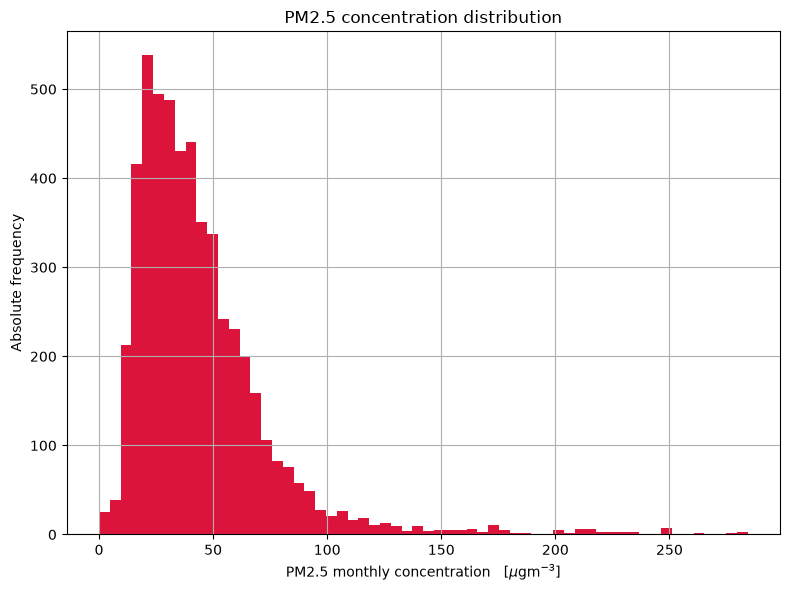

In [69]:
fig, ax = plt.subplots(figsize=(8,6))
gtruth_df["concentration_clean"].hist(bins=60, ax=ax, color="crimson")
ax.set_xlabel(r"PM2.5 monthly concentration   [$\mu$gm$^{-3}$]")
ax.set_ylabel("Absolute frequency")
ax.set_title("PM2.5 concentration distribution")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "pm25_conc_distribution.png", dpi=300)

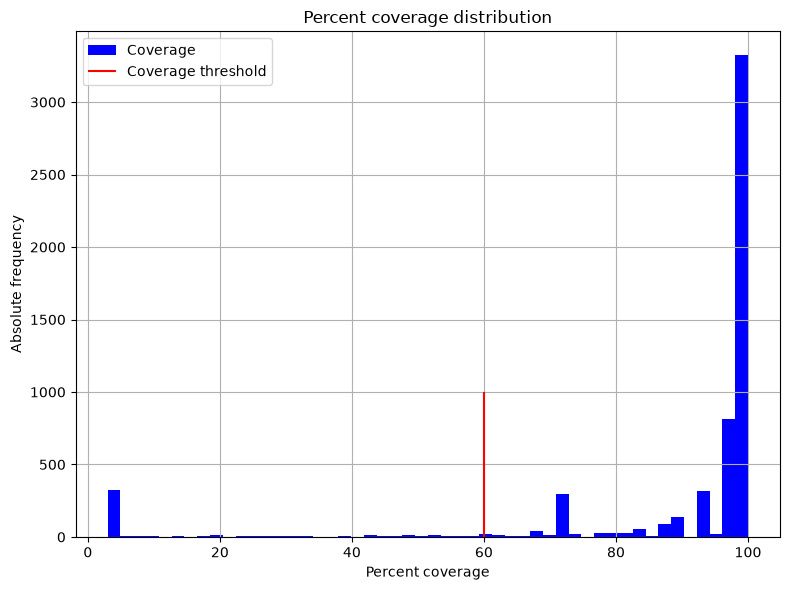

In [70]:
fig, ax = plt.subplots(figsize=(8,6))
gtruth_df["percent_coverage"].hist(bins=50, ax=ax, color="blue", label="Coverage")
ax.set_xlabel("Percent coverage")
ax.set_ylabel("Absolute frequency")
ax.set_title("Percent coverage distribution")
ax.vlines(COVERAGE_LIMIT, 0, 1000, color="red", label="Coverage threshold")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "percent_coverage_distribution.png", dpi=300)

The above plot justifies setting a coverage threshold at about 60%. It does not lose many stations, while retaining 
good significance.

In [71]:
gtruth_df.head()
print(f"Station with least NaN: {int(gtruth_df['concentration_clean'].isna().groupby(gtruth_df['station_id']).sum().idxmin())}, with {int(gtruth_df['concentration_clean'].isna().groupby(gtruth_df['station_id']).sum().min())} NaN out of 16")

Station with least NaN: 50, with 1 NaN out of 16


Find a pattern in the missing data where the measurement is missing (e.g. it was not set by me)

In [72]:
no_meas = gtruth_df["nan_reason"].value_counts()["no_measurement"] 
meas = gtruth_df["nan_reason"].value_counts()["none"] 
print(f"Fraction of NaN due to missing measurement: {no_meas / (no_meas + meas) :.3f}")

Fraction of NaN due to missing measurement: 0.021


In [73]:
# How many NaN due to no_measurement are there for each month across the dataset?
missing_months = (gtruth_df["nan_reason"]
                  .eq("no_measurement")  # True only where nan_reason is no_measurement
                  .groupby(gtruth_df["month"]) # The two series have aligned index so this works nicely
                  .mean() # The mean of a boolean series treats True as 1 and False as 0
                  .mul(100) # Turns to percentage
                 )
missing_months.name = "No measurement percentage"
missing_months

month
2025-03    0.290698
2025-04    1.744186
2025-05    1.744186
2025-06    1.744186
2025-07    2.034884
2025-08    2.034884
2025-09    1.162791
2025-10    1.453488
2025-11    1.453488
2025-12    1.453488
2026-01    1.744186
2026-02    1.744186
2026-03    1.744186
2026-04    1.744186
2026-05    1.453488
2026-06    1.453488
2026-07    7.558140
Freq: M, Name: No measurement percentage, dtype: float64

Plot a rough, model-independent distribution of where the stations are, and consequently where the monitoring deserts 
might be.

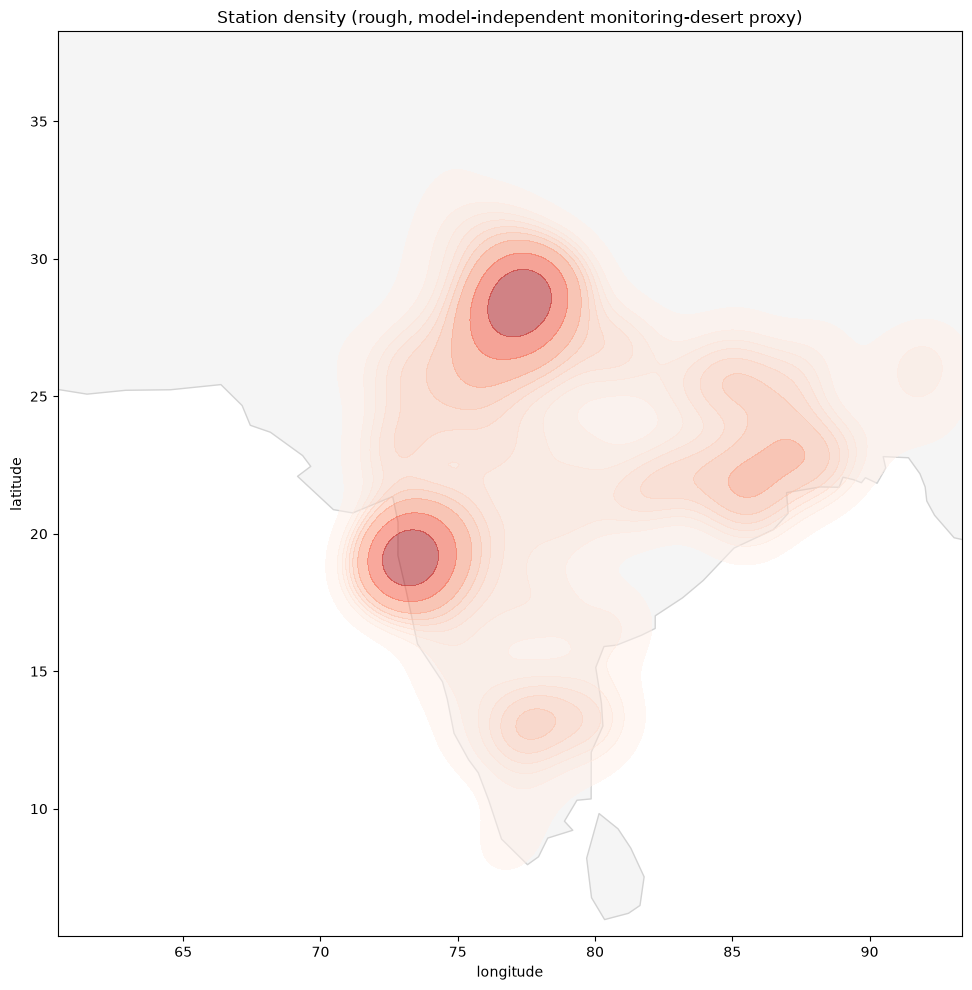

In [52]:
import geodatasets

# Country outlines as the background layer -- geopandas' old built-in sample datasets are
# gone in geopandas>=0.14, geodatasets is the maintained replacement. Both this and
# gtruth_df's longitude/latitude are plain WGS84 degrees (EPSG:4326), so no reprojection
# is needed to line them up.
world = gpd.read_file(geodatasets.get_path("naturalearth.land"))

fig, ax = plt.subplots(figsize=(10, 10))
world.plot(ax=ax, color="whitesmoke", edgecolor="lightgray")
sns.kdeplot(
    data=gtruth_df, x="longitude", y="latitude",
    fill=True, alpha=0.5, cmap="Reds", ax=ax,
)
# Crop to the study bounding box instead of showing the whole world.
ax.set_xlim(BOUNDING_BOX[0], BOUNDING_BOX[2])
ax.set_ylim(BOUNDING_BOX[1], BOUNDING_BOX[3])
ax.set_title("Station density (rough, model-independent monitoring-desert proxy)")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "../../maps/station_density_map.png", dpi=300)

## Step 5 - Save cleaned data

In [81]:
# Rename columns for downstream compatibility
gtruth_df = gtruth_df.rename(columns={"concentration_clean" : "pm25",
                                      "stdev" : "pm25_sd"
                                     }
                            )
# Save the full ground truth to the raw directory to speed up
# debugging if necessary
gtruth_df.to_parquet(RAW_DATA_DIR / "ground_truth_raw.parquet")

# Save the ground truth DataFrame to the clean data directory
# dropping columns that won't be necessary downstream
columns_to_save = ["station_id", "month", "longitude", "latitude",
                   "pm25", "pm25_sd", "unit", "nan_reason"
                  ]
gtruth_df[columns_to_save].to_parquet(CLEAN_DATA_DIR / "ground_truth_clean.parquet")

# Save miscellaneous metadata
metadata = {
    "concentration_limit" : CONC_LIMIT,
    "coverage_threshold" : COVERAGE_LIMIT,
    "dropped_rows" : {
        "no_measurement" : int(gtruth_df["nan_reason"].value_counts()["no_measurement"]),
        f"coverage_less_than_{round(COVERAGE_LIMIT)}%" : int(gtruth_df["nan_reason"].value_counts()[f"coverage_less_than_{round(COVERAGE_LIMIT)}%"]),
        f"value_greater_than_{round(CONC_LIMIT)}" : int(gtruth_df["nan_reason"].value_counts()[f"value_greater_than_{round(CONC_LIMIT)}"]),
        "non_positive" : int(gtruth_df["nan_reason"].value_counts()["non_positive"]),
    }
}
with open("../configs/ground_truth_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False) 

oaq_client.close()

End of notebook `02_ground_truth_extraction.ipynb`
___
Continue on notebook `03_satellite_features_extraction.ipynb`
